# Traffic Light Detection and Color Classification

A simple classical pipeline for task 3 of Lab 2A, built on the BDD100K 10k image dataset:

1. Lit lamp candidates from HSV color masks.
2. Each lamp is expanded into a few vertical housing boxes, and dark vertical blobs are added as housings of unlit lights.
3. A linear SVM on HOG, HSV histograms and geometry scores each box.
4. NMS and a score threshold chosen on validation.
5. The light color is read from the lamp masks inside the detected box.

In [1]:
import json
import zipfile
from pathlib import Path

import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.patches import Rectangle
from skimage.feature import hog
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import LinearSVC
from tqdm.auto import tqdm

RW_DIR = Path.home() / "rw"
OUTPUT_DIR = Path("outputs/traffic_lights")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

COLORS = ["red", "yellow", "green", "unknown"]
LAMP_COLORS = ["red", "yellow", "green"]
PLOT_COLORS = {"red": "red", "yellow": "gold", "green": "lime", "unknown": "white"}
CROP_SIZE = (20, 40)
NEGATIVES_PER_IMAGE = 40
IOU_THRESHOLD = 0.5
SEED = 42
rng = np.random.default_rng(SEED)

/home/krzys/rw/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## Data

In [2]:
images_zip = zipfile.ZipFile(RW_DIR / "bdd100k_images_10k.zip")
labels_zip = zipfile.ZipFile(RW_DIR / "bdd100k_labels.zip")

image_names = {Path(name).stem: name for name in images_zip.namelist() if name.endswith(".jpg")}
label_names = {Path(name).stem: name for name in labels_zip.namelist() if name.endswith(".json")}

splits = {"train": [], "val": [], "test": []}
for stem, name in sorted(image_names.items()):
    if stem in label_names:
        image_split = name.split("/")[1]
        label_split = label_names[stem].split("/")[1]
        splits["test" if image_split == "test" else label_split].append(stem)

{split: len(stems) for split, stems in splits.items()}

{'train': 2976, 'val': 454, 'test': 830}

In [3]:
def read_image(stem):
    data = np.frombuffer(images_zip.read(image_names[stem]), np.uint8)
    return cv2.cvtColor(cv2.imdecode(data, cv2.IMREAD_COLOR), cv2.COLOR_BGR2RGB)


def read_lights(stem):
    objects = json.loads(labels_zip.read(label_names[stem]))["frames"][0]["objects"]
    boxes, colors = [], []
    for obj in objects:
        box = obj.get("box2d")
        if obj["category"] == "traffic light" and box and box["x2"] > box["x1"] and box["y2"] > box["y1"]:
            boxes.append([box["x1"], box["y1"], box["x2"], box["y2"]])
            color = obj.get("attributes", {}).get("trafficLightColor", "none")
            colors.append(color if color in LAMP_COLORS else "unknown")
    return np.asarray(boxes, dtype=float).reshape(-1, 4), colors


truth = {stem: read_lights(stem) for split in splits.values() for stem in tqdm(split)}

rows = []
for split, stems in splits.items():
    for stem in stems:
        boxes, colors = truth[stem]
        for box, color in zip(boxes, colors):
            rows.append({"split": split, "color": color, "width": box[2] - box[0], "height": box[3] - box[1]})
lights = pd.DataFrame(rows)
pd.crosstab(lights["split"], lights["color"], margins=True)


  0%|          | 0/2976 [00:00<?, ?it/s]


 33%|███▎      | 974/2976 [00:00<00:00, 9738.96it/s]


 65%|██████▌   | 1948/2976 [00:00<00:00, 9166.45it/s]


 96%|█████████▋| 2867/2976 [00:00<00:00, 8591.42it/s]


100%|██████████| 2976/2976 [00:00<00:00, 8749.59it/s]


  0%|          | 0/454 [00:00<?, ?it/s]


100%|██████████| 454/454 [00:00<00:00, 7215.64it/s]


  0%|          | 0/830 [00:00<?, ?it/s]


100%|██████████| 830/830 [00:00<00:00, 8363.64it/s]

color,green,red,unknown,yellow,All
split,,,,,
test,739,372,1021,27,2159
train,2576,1209,3430,173,7388
val,388,193,587,23,1191
All,3703,1774,5038,223,10738


In [4]:
lights[["width", "height"]].describe(percentiles=[0.1, 0.25, 0.5, 0.75, 0.9]).round(1)

,width,height
count,10738.0,10738.0
mean,15.7,26.7
std,10.3,16.7
min,1.0,2.0
10%,7.0,11.8
25%,9.0,15.0
50%,13.2,21.6
75%,19.5,33.7
90%,27.5,48.9
max,373.2,316.6


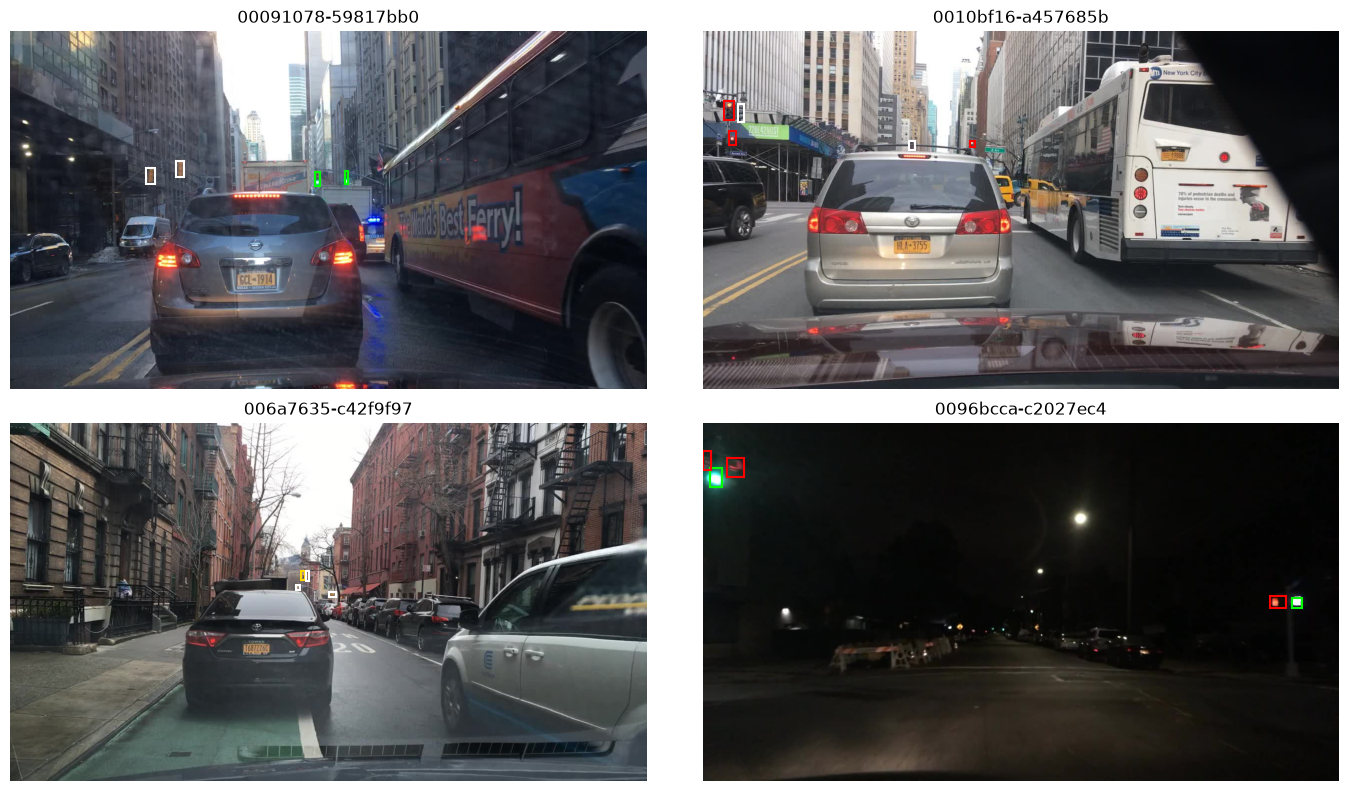

In [5]:
def draw_boxes(ax, boxes, colors, linestyle="-"):
    for box, color in zip(boxes, colors):
        ax.add_patch(Rectangle(box[:2], box[2] - box[0], box[3] - box[1], fill=False, edgecolor=PLOT_COLORS[color], linewidth=1.5, linestyle=linestyle))


examples = [stem for stem in splits["train"] if len(truth[stem][0]) >= 3][:4]
fig, axes = plt.subplots(2, 2, figsize=(14, 8))
for ax, stem in zip(axes.flat, examples):
    ax.imshow(read_image(stem))
    draw_boxes(ax, *truth[stem])
    ax.set_title(stem)
    ax.axis("off")
plt.tight_layout()
plt.show()

## Candidate generation

A lit lamp is a small, bright, saturated blob. For every blob we propose vertical housing boxes at a few scales and aspect ratios, with the lamp in the top, middle or bottom slot, plus a square box for single-lamp lights. Unlit lights (`unknown`) have no bright lamp, so we also add dark, vertical blobs from the upper part of the image as housing candidates.

In [6]:
LAMP_RANGES = {
    "red": [((0, 80, 150), (10, 255, 255)), ((160, 80, 150), (179, 255, 255))],
    "yellow": [((11, 80, 150), (34, 255, 255))],
    "green": [((45, 60, 150), (100, 255, 255))],
}
LAMP_SCALES = (1.4, 2.0, 2.8)
HOUSING_RATIOS = (1.6, 2.2, 3.0)


def color_masks(image):
    hsv = cv2.cvtColor(image, cv2.COLOR_RGB2HSV)
    masks = {}
    for color, ranges in LAMP_RANGES.items():
        mask = np.zeros(hsv.shape[:2], np.uint8)
        for low, high in ranges:
            mask |= cv2.inRange(hsv, low, high)
        masks[color] = mask
    return masks


def lamp_blobs(masks, image_height):
    blobs = []
    for color, mask in masks.items():
        _, _, stats, _ = cv2.connectedComponentsWithStats(mask)
        for x, y, w, h, area in stats[1:]:
            if 2 <= w <= 40 and 2 <= h <= 40 and 0.5 <= w / h <= 2 and area >= 0.4 * w * h and y < 0.7 * image_height:
                blobs.append((x + w / 2, y + h / 2, max(w, h)))
    return blobs


def dark_housing_boxes(image):
    height = image.shape[0]
    value = cv2.cvtColor(image, cv2.COLOR_RGB2HSV)[:, :, 2]
    boxes = []
    for max_value in (50, 80):
        mask = (value < max_value).astype(np.uint8)
        mask[int(0.65 * height):] = 0
        _, _, stats, _ = cv2.connectedComponentsWithStats(mask)
        for x, y, w, h, area in stats[1:]:
            if 4 <= w <= 60 and 8 <= h <= 120 and 1.2 <= h / w <= 4 and area >= 0.5 * w * h:
                for pad in (0, 0.15):
                    boxes.append([x - pad * w, y - pad * h, x + w + pad * w, y + h + pad * h])
    return boxes


def candidate_boxes(image):
    height, width = image.shape[:2]
    masks = color_masks(image)
    boxes = dark_housing_boxes(image)
    for cx, cy, size in lamp_blobs(masks, height):
        for scale in LAMP_SCALES:
            box_width = scale * size
            boxes.append([cx - box_width / 2, cy - box_width / 2, cx + box_width / 2, cy + box_width / 2])
            for ratio in HOUSING_RATIOS:
                box_height = ratio * box_width
                for slot in range(3):
                    top = cy - box_height * (slot + 0.5) / 3
                    boxes.append([cx - box_width / 2, top, cx + box_width / 2, top + box_height])
    boxes = np.asarray(boxes, dtype=float).reshape(-1, 4)
    boxes = np.clip(boxes, 0, [width, height, width, height])
    keep = (boxes[:, 2] - boxes[:, 0] >= 2) & (boxes[:, 3] - boxes[:, 1] >= 2)
    return boxes[keep], masks


def iou(box, boxes):
    if len(boxes) == 0:
        return np.zeros(0)
    x1 = np.maximum(box[0], boxes[:, 0])
    y1 = np.maximum(box[1], boxes[:, 1])
    x2 = np.minimum(box[2], boxes[:, 2])
    y2 = np.minimum(box[3], boxes[:, 3])
    intersection = np.clip(x2 - x1, 0, None) * np.clip(y2 - y1, 0, None)
    area = (box[2] - box[0]) * (box[3] - box[1])
    areas = (boxes[:, 2] - boxes[:, 0]) * (boxes[:, 3] - boxes[:, 1])
    return intersection / (area + areas - intersection)


def best_iou(boxes, reference):
    if len(reference) == 0:
        return np.zeros(len(boxes))
    return np.asarray([iou(box, reference).max() for box in boxes])

In [7]:
coverage_rows, candidate_counts = [], []
for stem in tqdm(splits["val"]):
    boxes, _ = candidate_boxes(read_image(stem))
    candidate_counts.append(len(boxes))
    gt_boxes, gt_colors = truth[stem]
    for gt_box, color in zip(gt_boxes, gt_colors):
        coverage_rows.append({"color": color, "covered": iou(gt_box, boxes).max(initial=0) >= IOU_THRESHOLD})
coverage = pd.DataFrame(coverage_rows)
print(f"Candidates per image: {np.mean(candidate_counts):.0f}")
print(f"Coverage at IoU >= {IOU_THRESHOLD}: {coverage['covered'].mean():.1%}")
coverage.groupby("color")["covered"].agg(["mean", "size"]).round(3)


  0%|          | 0/454 [00:00<?, ?it/s]


  1%|          | 4/454 [00:00<00:11, 39.88it/s]


  2%|▏         | 9/454 [00:00<00:11, 39.45it/s]


  3%|▎         | 14/454 [00:00<00:10, 40.50it/s]


  4%|▍         | 19/454 [00:00<00:10, 41.06it/s]


  5%|▌         | 24/454 [00:00<00:12, 35.69it/s]

... (90 outputs left out)


100%|█████████▉| 453/454 [00:12<00:00, 35.01it/s]


100%|██████████| 454/454 [00:12<00:00, 37.64it/s]

Candidates per image: 2196
Coverage at IoU >= 0.5: 44.9%


,mean,size
color,,
green,0.639,388
red,0.663,193
unknown,0.239,587
yellow,0.826,23


## Features and classifier

Each candidate is resized to 20×40 and described by HOG of the grayscale crop, HSV histograms, the share of each lamp mask, darkness of the housing and the box geometry.

In [8]:
def clip_box(box, width, height):
    x1 = int(np.clip(np.floor(box[0]), 0, width - 1))
    y1 = int(np.clip(np.floor(box[1]), 0, height - 1))
    x2 = int(np.clip(np.ceil(box[2]), x1 + 1, width))
    y2 = int(np.clip(np.ceil(box[3]), y1 + 1, height))
    return x1, y1, x2, y2


def lamp_fractions(masks, box):
    x1, y1, x2, y2 = box
    return [masks[color][y1:y2, x1:x2].mean() / 255 for color in LAMP_COLORS]


def crop_features(image, masks, box):
    height, width = image.shape[:2]
    x1, y1, x2, y2 = clip_box(box, width, height)
    crop = cv2.resize(image[y1:y2, x1:x2], CROP_SIZE, interpolation=cv2.INTER_AREA)
    gray = cv2.cvtColor(crop, cv2.COLOR_RGB2GRAY)
    hsv = cv2.cvtColor(crop, cv2.COLOR_RGB2HSV)
    shape = hog(gray, orientations=9, pixels_per_cell=(5, 5), cells_per_block=(2, 2), block_norm="L2-Hys")
    histograms = [np.histogram(hsv[:, :, channel], bins=8, range=(0, upper))[0] / gray.size for channel, upper in enumerate((180, 256, 256))]
    darkness = [(hsv[:, :, 2] < 60).mean(), hsv[:, :, 2].mean() / 255]
    geometry = [np.log((x2 - x1) / (y2 - y1)), np.log(x2 - x1), y1 / height]
    return np.concatenate([shape, *histograms, lamp_fractions(masks, (x1, y1, x2, y2)), darkness, geometry]).astype(np.float32)


def image_features(image, masks, boxes):
    return np.asarray([crop_features(image, masks, box) for box in boxes], dtype=np.float32)

In [9]:
features, targets = [], []
for stem in tqdm(splits["train"]):
    image = read_image(stem)
    boxes, masks = candidate_boxes(image)
    gt_boxes, _ = truth[stem]
    overlap = best_iou(boxes, gt_boxes)
    positives = np.vstack([boxes[overlap >= IOU_THRESHOLD], gt_boxes])
    negatives = boxes[overlap < 0.2]
    negatives = negatives[rng.permutation(len(negatives))[:NEGATIVES_PER_IMAGE]]
    for group, target in ((positives, 1), (negatives, 0)):
        if len(group):
            features.append(image_features(image, masks, group))
            targets.append(np.full(len(group), target))
X_train = np.vstack(features)
y_train = np.concatenate(targets)
print(X_train.shape, f"positives: {y_train.sum()}, negatives: {(y_train == 0).sum()}")


  0%|          | 0/2976 [00:00<?, ?it/s]


  0%|          | 2/2976 [00:00<04:35, 10.78it/s]


  0%|          | 4/2976 [00:00<04:48, 10.31it/s]


  0%|          | 6/2976 [00:00<04:33, 10.88it/s]


  0%|          | 8/2976 [00:00<05:13,  9.48it/s]


  0%|          | 9/2976 [00:00<05:48,  8.53it/s]

... (1,260 outputs left out)


100%|█████████▉| 2971/2976 [03:12<00:00, 18.53it/s]


100%|█████████▉| 2974/2976 [03:12<00:00, 19.91it/s]


100%|██████████| 2976/2976 [03:12<00:00, 15.48it/s]

(143348, 788) positives: 24933, negatives: 118415


In [10]:
model = make_pipeline(StandardScaler(), LinearSVC(C=0.01, class_weight="balanced", max_iter=5000))
model.fit(X_train, y_train)
print(f"Train accuracy: {model.score(X_train, y_train):.3f}")

Train accuracy: 0.853


## Detection, color and evaluation

Boxes above the score threshold go through NMS. The color of a detection is the lamp color with the largest mask share inside the box, or `unknown` when no lamp color covers at least 2% of it.

In [11]:
def nms(boxes, scores, threshold=0.3):
    order = np.argsort(-scores)
    keep = []
    while len(order):
        current = order[0]
        keep.append(current)
        order = order[1:][iou(boxes[current], boxes[order[1:]]) < threshold]
    return np.asarray(keep, dtype=int)


def light_color(masks, box, image_shape, min_fraction=0.02):
    fractions = lamp_fractions(masks, clip_box(box, image_shape[1], image_shape[0]))
    best = int(np.argmax(fractions))
    return LAMP_COLORS[best] if fractions[best] >= min_fraction else "unknown"


def score_image(stem):
    image = read_image(stem)
    boxes, masks = candidate_boxes(image)
    if len(boxes) == 0:
        return boxes, np.zeros(0), []
    scores = model.decision_function(image_features(image, masks, boxes))
    colors = [light_color(masks, box, image.shape) for box in boxes]
    return boxes, scores, colors


def detect(scored, threshold):
    boxes, scores, colors = scored
    selected = np.flatnonzero(scores >= threshold)
    if len(selected) == 0:
        return np.zeros((0, 4)), np.zeros(0), []
    keep = selected[nms(boxes[selected], scores[selected])]
    return boxes[keep], scores[keep], [colors[k] for k in keep]


def match(pred_boxes, gt_boxes):
    matched_gt = set()
    pairs = []
    for index, box in enumerate(pred_boxes):
        overlaps = iou(box, gt_boxes)
        for gt_index in np.argsort(-overlaps):
            if overlaps[gt_index] < IOU_THRESHOLD:
                break
            if gt_index not in matched_gt:
                matched_gt.add(gt_index)
                pairs.append((index, gt_index))
                break
    return pairs


def evaluate(scored_images, threshold):
    tp = fp = fn = 0
    for stem, scored in scored_images.items():
        pred_boxes, _, _ = detect(scored, threshold)
        gt_boxes, _ = truth[stem]
        matches = len(match(pred_boxes, gt_boxes))
        tp += matches
        fp += len(pred_boxes) - matches
        fn += len(gt_boxes) - matches
    precision = tp / max(tp + fp, 1)
    recall = tp / max(tp + fn, 1)
    f1 = 2 * precision * recall / max(precision + recall, 1e-9)
    return {"threshold": threshold, "tp": tp, "fp": fp, "fn": fn, "precision": precision, "recall": recall, "f1": f1}

In [12]:
val_scored = {stem: score_image(stem) for stem in tqdm(splits["val"])}
thresholds = np.round(np.arange(-0.5, 2.51, 0.1), 2)
val_results = pd.DataFrame([evaluate(val_scored, threshold) for threshold in thresholds])
best_threshold = float(val_results.loc[val_results["f1"].idxmax(), "threshold"])
print(f"Best threshold on val: {best_threshold}")
val_results.sort_values("f1", ascending=False).head(5).round(3)


  0%|          | 0/454 [00:00<?, ?it/s]


  0%|          | 1/454 [00:01<09:23,  1.24s/it]


  0%|          | 2/454 [00:01<06:52,  1.10it/s]


  1%|          | 3/454 [00:06<21:04,  2.80s/it]


  1%|          | 4/454 [00:07<13:01,  1.74s/it]


  1%|          | 5/454 [00:07<08:46,  1.17s/it]

... (433 outputs left out)


100%|██████████| 454/454 [10:02<00:00,  2.33s/it]


100%|██████████| 454/454 [10:02<00:00,  1.33s/it]

Best threshold on val: 1.2


,threshold,tp,fp,fn,precision,recall,f1
17,1.2,178,1574,1013,0.102,0.149,0.121
18,1.3,140,1104,1051,0.113,0.118,0.115
16,1.1,200,2219,991,0.083,0.168,0.111
19,1.4,114,768,1077,0.129,0.096,0.110
20,1.5,95,495,1096,0.161,0.080,0.107


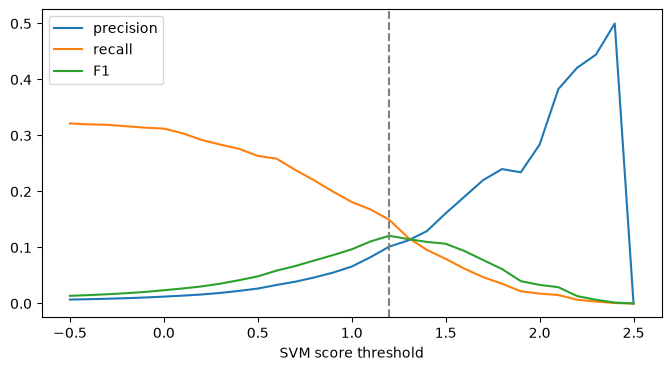

In [13]:
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(val_results["threshold"], val_results["precision"], label="precision")
ax.plot(val_results["threshold"], val_results["recall"], label="recall")
ax.plot(val_results["threshold"], val_results["f1"], label="F1")
ax.axvline(best_threshold, color="gray", linestyle="--")
ax.set_xlabel("SVM score threshold")
ax.legend()
plt.show()

## Test results

In [14]:
test_scored = {stem: score_image(stem) for stem in tqdm(splits["test"])}
test_metrics = evaluate(test_scored, best_threshold)
pd.DataFrame([test_metrics]).round(3)


  0%|          | 0/830 [00:00<?, ?it/s]


  0%|          | 1/830 [00:03<52:31,  3.80s/it]


  0%|          | 2/830 [00:06<41:16,  2.99s/it]


  0%|          | 3/830 [00:06<25:19,  1.84s/it]


  0%|          | 4/830 [00:07<19:24,  1.41s/it]


  1%|          | 5/830 [00:08<17:22,  1.26s/it]

... (795 outputs left out)


100%|█████████▉| 829/830 [18:24<00:00,  1.14it/s]


100%|██████████| 830/830 [18:26<00:00,  1.18s/it]


100%|██████████| 830/830 [18:26<00:00,  1.33s/it]

,threshold,tp,fp,fn,precision,recall,f1
0,1.2,288,2728,1871,0.095,0.133,0.111


In [15]:
rows, predictions = [], {}
for stem, scored in test_scored.items():
    pred_boxes, pred_scores, pred_colors = detect(scored, best_threshold)
    gt_boxes, gt_colors = truth[stem]
    pairs = match(pred_boxes, gt_boxes)
    matched_pred = {index for index, _ in pairs}
    matched_gt = {gt_index for _, gt_index in pairs}
    for index, gt_index in pairs:
        rows.append({"stem": stem, "kind": "TP", "box": pred_boxes[index], "score": pred_scores[index], "pred_color": pred_colors[index], "true_color": gt_colors[gt_index]})
    for index in range(len(pred_boxes)):
        if index not in matched_pred:
            rows.append({"stem": stem, "kind": "FP", "box": pred_boxes[index], "score": pred_scores[index], "pred_color": pred_colors[index], "true_color": None})
    for gt_index in range(len(gt_boxes)):
        if gt_index not in matched_gt:
            rows.append({"stem": stem, "kind": "FN", "box": gt_boxes[gt_index], "score": np.nan, "pred_color": None, "true_color": gt_colors[gt_index]})
    predictions[stem] = [
        {"box": [round(float(v), 1) for v in box], "score": round(float(score), 4), "color": color}
        for box, score, color in zip(pred_boxes, pred_scores, pred_colors)
    ]
results = pd.DataFrame(rows)
(OUTPUT_DIR / "test_predictions.json").write_text(json.dumps({"threshold": best_threshold, "metrics": test_metrics, "predictions": predictions}, indent=1))
results["kind"].value_counts()

kind
FP    2728
FN    1871
TP     288
Name: count, dtype: int64

### Color accuracy on correctly localized lights

In [16]:
tp = results[results["kind"] == "TP"]
print(f"Color accuracy: {(tp['pred_color'] == tp['true_color']).mean():.1%} on {len(tp)} lights")
pd.crosstab(tp["true_color"], tp["pred_color"], rownames=["true"], colnames=["predicted"]).reindex(index=COLORS, columns=COLORS, fill_value=0)

Color accuracy: 70.5% on 288 lights


predicted,red,yellow,green,unknown
true,,,,
red,25,23,1,0
yellow,0,4,1,0
green,1,23,168,0
unknown,2,27,7,6


In [17]:
results[results["kind"] == "FN"]["true_color"].value_counts().rename("missed")

true_color
unknown    979
green      547
red        323
yellow      22
Name: missed, dtype: int64

## Error examples

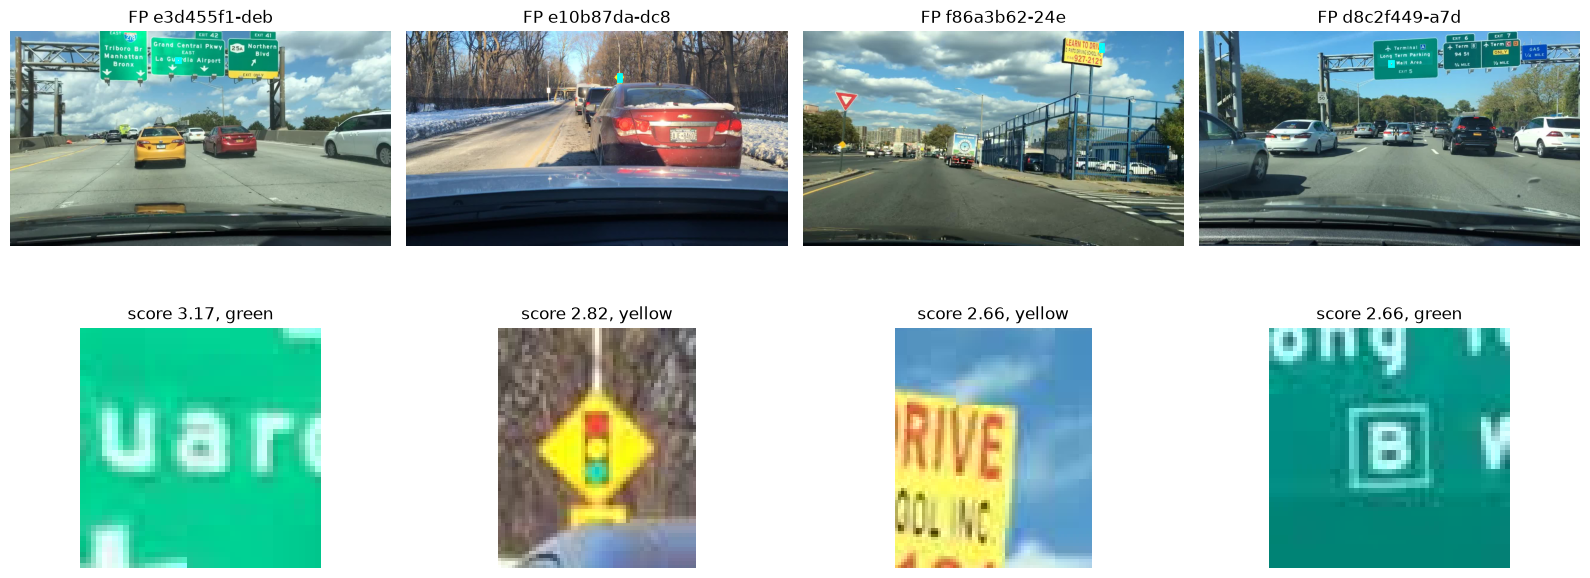

In [18]:
def show_errors(kind, count=4):
    errors = results[results["kind"] == kind]
    if kind == "FP":
        errors = errors.sort_values("score", ascending=False)
    else:
        errors = errors.assign(area=errors["box"].map(lambda b: (b[2] - b[0]) * (b[3] - b[1]))).sort_values("area", ascending=False)
    errors = errors.drop_duplicates("stem").head(count)
    fig, axes = plt.subplots(2, count, figsize=(4 * count, 7), gridspec_kw={"height_ratios": [2, 1]})
    for column, (_, row) in enumerate(errors.iterrows()):
        image = read_image(row["stem"])
        box = row["box"]
        axes[0, column].imshow(image)
        draw_boxes(axes[0, column], *truth[row["stem"]], linestyle="--")
        axes[0, column].add_patch(Rectangle(box[:2], box[2] - box[0], box[3] - box[1], fill=False, edgecolor="cyan", linewidth=2))
        axes[0, column].set_title(f"{kind} {row['stem'][:12]}")
        x1, y1, x2, y2 = clip_box(box, image.shape[1], image.shape[0])
        pad = max(x2 - x1, y2 - y1)
        axes[1, column].imshow(image[max(y1 - pad, 0):y2 + pad, max(x1 - pad, 0):x2 + pad])
        label = f"score {row['score']:.2f}, {row['pred_color']}" if kind == "FP" else f"true {row['true_color']}"
        axes[1, column].set_title(label)
        for ax in axes[:, column]:
            ax.axis("off")
    plt.tight_layout()
    plt.show()


show_errors("FP")

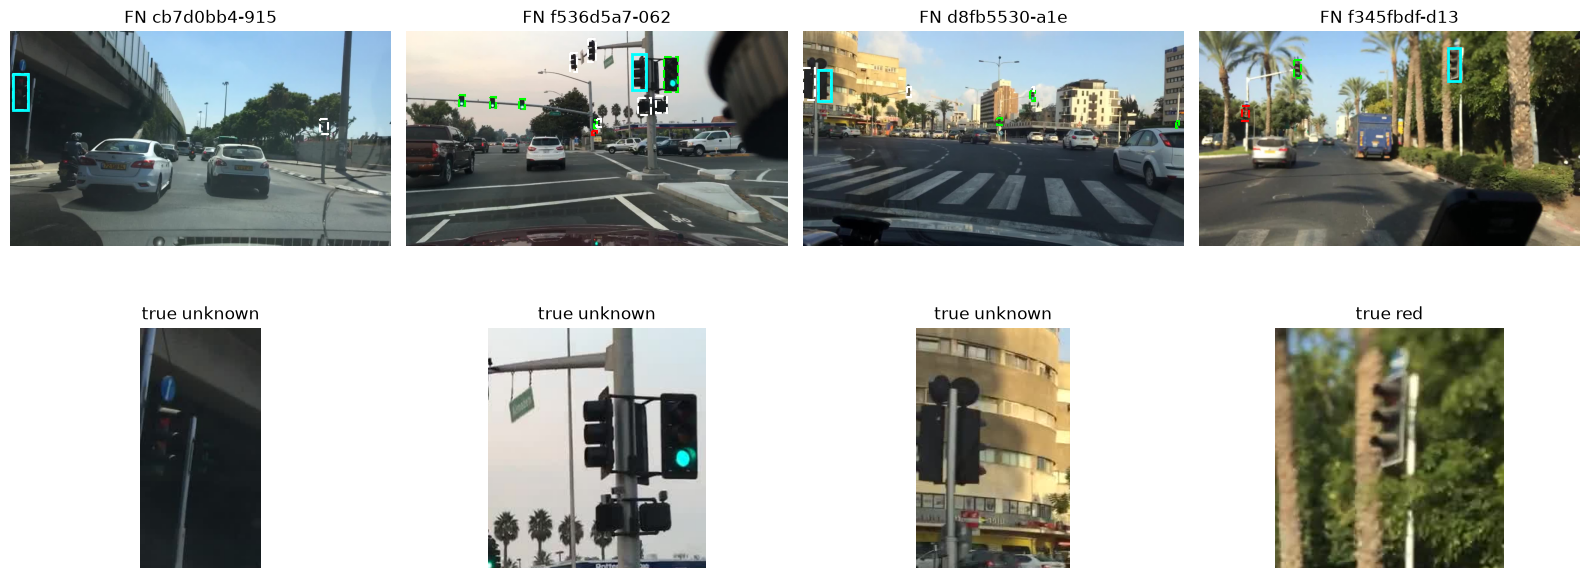

In [19]:
show_errors("FN")

## Conclusions

- **Detection on test (830 images, 2159 lights):** at threshold `1.2` (selected on val, where F1 = 0.121), the detector reaches **precision 0.095, recall 0.133, F1 0.111** (288 TP, 2728 FP, 1871 FN).
- **Candidate ceiling:** the HSV lamp + dark-housing generator averages ~2196 proposals/image and covers **44.9%** of validation lights at IoU ≥ 0.5 — reasonable on lit lights (63.9% green, 66.3% red, 82.6% yellow), but only **23.9%** on `unknown` (unlit/side-view/tiny) lights, which make up 47% of the dataset and 979 of 1871 missed test lights.
- **False positives:** training a linear SVM on a single round of sampled negatives (24.9k positives vs 118.4k negatives) leaves 2728 FPs (~3.3/image) on taillights, signs, and bright background objects. One or two rounds of hard-negative mining and a non-linear model (e.g. GBDT/RBF SVM) would raise precision substantially.
- **Color classification on TPs:** **70.5%** accuracy overall (168/192 green, 25/49 red, 4/5 yellow, 6/42 unknown). Most errors go into `yellow` (23 red, 23 green, 27 unknown) because the yellow HSV hue band catches warm headlights, orange-red lamps, and sunlit housings; tightening the yellow hue/saturation thresholds or classifying color from lamp vertical position inside the housing would help.